In [ ]:
import mdtraj as md
import os
import matplotlib.pyplot as plt
import numpy as np

PCA analysis: Concatenate trajectories. Compute the pairwise distances between residues in a trajectory. Flatten these distances, then perform PCA on these distances. PCA finds the components that explain the most variance in the data.

In [ ]:
# Concatenate the finished 1 us replicas of each system back to back into one trajectory per system.
# Uses the thinned, dry trajectories from section 2 (protein + TMP + NADPH, one frame per ns), so `runs` must be defined
import shutil

CONCAT_DIR = os.path.join(RUNS, "combined_1us")
os.makedirs(CONCAT_DIR, exist_ok=True)

concat = {}             # system -> (dry pdb, concatenated xtc)
replica_of_frame = {}   # system -> replica name for every frame of the concatenated trajectory (for coloring PCA later)
for system in ["wt", "m20i"]:
    names = sorted(n for n in runs if n.startswith(f"{system}_with_ligands_1us_"))   # replicas in order: 01, 02, 03, 05
    pdb = runs[names[0]][0]   # all replicas of a system have the same atoms in the same order
    trajs = [md.load(runs[n][1], top=pdb) for n in names]
    joined = md.join(trajs, check_topology=True)
    joined.time = np.arange(joined.n_frames) * (trajs[0].time[1] - trajs[0].time[0])   # continuous time: 0, 1, 2, ... ns

    tag = f"{system}_with_ligands_1us_{len(names)}reps"
    out_xtc = os.path.join(CONCAT_DIR, f"{tag}.xtc")
    out_pdb = os.path.join(CONCAT_DIR, f"{tag}_dry.pdb")   # topology to load the concatenated trajectory with
    joined.save_xtc(out_xtc)
    shutil.copy(pdb, out_pdb)
    concat[system] = (out_pdb, out_xtc)
    replica_of_frame[system] = np.concatenate([[n] * t.n_frames for n, t in zip(names, trajs)])

    print(f"{system}: {joined.n_frames} frames, {joined.n_atoms} atoms -> {out_xtc}")
    start = 0
    for n, t in zip(names, trajs):
        print(f"    frames {start:4d}-{start + t.n_frames - 1:4d}: {n}")
        start += t.n_frames

wt: 4000 frames, 2604 atoms -> /n/home00/ewang03/scratch/GroEL/runs/combined_1us/wt_with_ligands_1us_4reps.xtc
    frames    0- 999: wt_with_ligands_1us_01
    frames 1000-1999: wt_with_ligands_1us_02
    frames 2000-2999: wt_with_ligands_1us_03
    frames 3000-3999: wt_with_ligands_1us_05
m20i: 4000 frames, 2606 atoms -> /n/home00/ewang03/scratch/GroEL/runs/combined_1us/m20i_with_ligands_1us_4reps.xtc
    frames    0- 999: m20i_with_ligands_1us_01
    frames 1000-1999: m20i_with_ligands_1us_02
    frames 2000-2999: m20i_with_ligands_1us_03
    frames 3000-3999: m20i_with_ligands_1us_05


In [ ]:
# compute pairwise distances 
m20i_traj = md.load("/n/home00/ewang03/scratch/GroEL/runs/combined_1us/m20i_with_ligands_1us_4reps.xtc", 
                    top="/n/home00/ewang03/scratch/GroEL/runs/2026-11-07_58169745/m20i_nadph_tmp_dry.pdb")
wt_traj = md.load("/n/home00/ewang03/scratch/GroEL/runs/combined_1us/wt_with_ligands_1us_4reps.xtc",
                  top="/n/home00/ewang03/scratch/GroEL/runs/2026-11-07_58169764/wt_nadph_tmp_dry.pdb")

trajs = {"m20i": m20i_traj, "wt": wt_traj}
dist = {}
pairs = {}
for name, traj in trajs.items():
    dist[name], pairs[name] = md.compute_contacts(traj, scheme='ca')   # (n_frames, n_pairs) in nm, (n_pairs, 2)

# WT and M20I must use the same residue pairs in the same order, so they can share one PCA
assert np.array_equal(pairs["m20i"], pairs["wt"])
print(dist["m20i"].shape)   # (4000, 12246)

(4000, 12246)


In [ ]:
#np.allclose(pairs["m20i"], pairs["wt"])
print(pairs["m20i"])

[[  0   3]
 [  0   4]
 [  0   5]
 ...
 [154 157]
 [154 158]
 [155 158]]


explained variance: PC1 16.3%, PC2 8.0%
explained variance: PC1 13.8%, PC2 10.6%


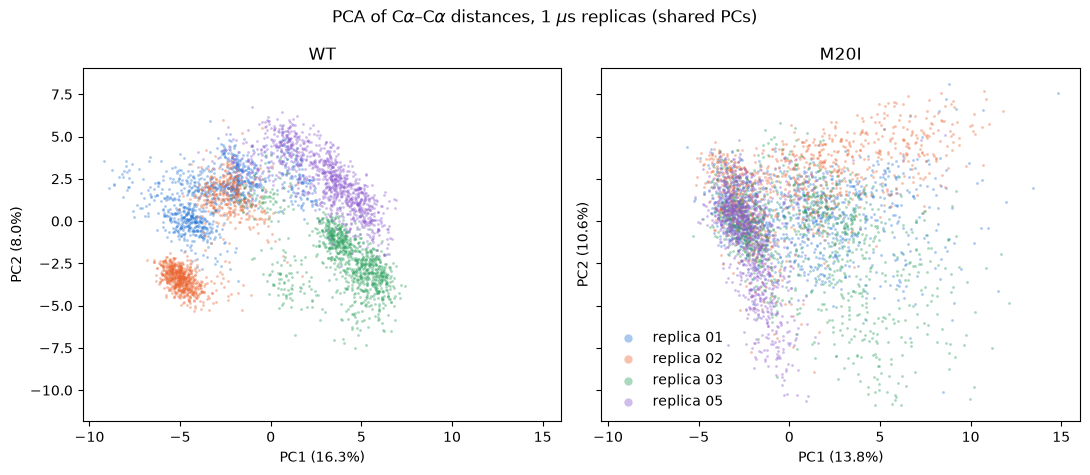

In [ ]:
# PCA on the CA-CA distances.
# Fit ONE PCA on WT + M20I frames together, then project each system onto it. Both plots then share the same
# PC1/PC2 axes, so a shift between WT and M20I is a real difference (separate fits give axes that can't be compared)
from sklearn.decomposition import PCA

systems_pca = [("wt", "WT"), ("m20i", "M20I")]
proj = {}
var_dict = {}
for sys in systems_pca:
    X = np.vstack([dist[sys[0]]]) 
    pca = PCA(n_components=25)
    pca.fit(X)
    proj[sys[0]] = pca.transform(dist[sys[0]]) 

    var_dict[sys[0]] = pca.explained_variance_ratio_ * 100
    print(f"explained variance: PC1 {var_dict[sys[0]][0]:.1f}%, PC2 {var_dict[sys[0]][1]:.1f}%")

# Replica of each frame: the concatenated trajectories are 4 replicas x 1000 frames, in the order 01, 02, 03, 05
rep_names = ["01", "02", "03", "05"]
frames_per_rep = 1000
assert all(len(proj[s]) == len(rep_names) * frames_per_rep for s, _ in systems_pca)
rep_colors = ["#2a78d6", "#eb6834", "#2ca25f", "#8e5bd0"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
for ax, (system, label) in zip(axes, systems_pca):
    p = proj[system]
    var = var_dict[system]
    for k, (rep, color) in enumerate(zip(rep_names, rep_colors)):
        sl = slice(k * frames_per_rep, (k + 1) * frames_per_rep)
        ax.scatter(p[sl, 0], p[sl, 1], s=4, alpha=0.4, color=color, lw=0, label=f"replica {rep}")
    ax.set_title(label)
    ax.set_xlabel(f"PC1 ({var[0]:.1f}%)")
    #ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylabel(f"PC2 ({var[1]:.1f}%)")
axes[1].legend(frameon=False, markerscale=3, loc="best")
fig.suptitle(r"PCA of C$\alpha$–C$\alpha$ distances, 1 $\mu$s replicas (shared PCs)")
fig.tight_layout()
plt.show()

In [ ]:
pca.components_[0, :]

array([ 0.0003588 ,  0.00012112,  0.00040999, ..., -0.00011505,
        0.00074179,  0.00105712], shape=(12246,), dtype=float32)

In [ ]:
pca_dict = {}
pca_comp = pca.components_[0, :]

for i, pair in enumerate(pairs["m20i"]):
    pca_dict[(pair[0], pair[1])] = pca_comp[i]

pca_dict =  dict(sorted(pca_dict.items(), key=lambda item: np.abs(item[1]), reverse=True))
print(pca_dict)


{(np.int64(17), np.int64(65)): np.float32(0.053998716), (np.int64(17), np.int64(62)): np.float32(0.053254105), (np.int64(17), np.int64(75)): np.float32(0.053208947), (np.int64(17), np.int64(43)): np.float32(0.053105596), (np.int64(17), np.int64(44)): np.float32(0.052878268), (np.int64(17), np.int64(63)): np.float32(0.05264433), (np.int64(17), np.int64(74)): np.float32(0.052528314), (np.int64(17), np.int64(61)): np.float32(0.0524291), (np.int64(17), np.int64(64)): np.float32(0.052027877), (np.int64(17), np.int64(42)): np.float32(0.05155952), (np.int64(17), np.int64(66)): np.float32(0.051424187), (np.int64(17), np.int64(76)): np.float32(0.05131914), (np.int64(17), np.int64(79)): np.float32(0.051247973), (np.int64(17), np.int64(73)): np.float32(0.05113372), (np.int64(17), np.int64(60)): np.float32(0.050488696), (np.int64(17), np.int64(80)): np.float32(0.05028578), (np.int64(17), np.int64(82)): np.float32(0.049638417), (np.int64(17), np.int64(83)): np.float32(0.04946091), (np.int64(17), np

In [ ]:
print(pca.explained_variance_ratio_)

[0.11605938 0.09071849 0.07652455 0.05646937 0.05175182 0.04966548
 0.03197636 0.02464476 0.02281197 0.02057525 0.019633   0.01795205
 0.01716221 0.01592113 0.01530977 0.01456769 0.01250777 0.01203714
 0.01095414 0.01001734 0.00963553 0.00923701 0.00852837 0.0078141
 0.00763622]
